# Feature tour

Every feature of `convergence_clubs`, each with its output. Read it on GitHub as it is, or run
it yourself; the test suite runs it on every change, so the code always works.

For the method itself and how to interpret each result, start with the
[tutorial](tutorial.ipynb); the [guides](guide/) cover every option.

| Section | What it shows |
|---|---|
| 1. Data | bundled panels, long format, missing values, HP filter |
| 2. The log t test | whole-panel convergence |
| 3. Clubs | clustering, merging, divergent units, R and Stata conventions, renaming |
| 4. Plots | transition paths, diagnostics, themes, style |
| 5. Robustness | sensitivity grid, bootstrap, clubs over time, parallel runs |
| 6. Classical convergence | β, σ, distribution dynamics, Pesaran's pairwise test |
| 7. Determinants | ordered logit of club membership |
| 8. Output | interactive charts, maps and spatial clustering, report, command line, LaTeX tables |

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import convergence_clubs as cc

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 80  # keeps the saved notebook small
cc.__version__

'0.1.0'

## 1. Data

Two panels ship with the package: GDP per capita of 152 countries (Phillips and Sul, 2009) and
the Penn World Table productivity panel of Mendez (2020). The data are a DataFrame with **units
in rows** and **periods in columns**.

In [2]:
gdp = cc.load_gdp()  # levels, 152 countries x 1970-2003
gdp.iloc[:4, :6]

year,1970,1971,1972,1973,1974,1975
Countries,,,,,,
Afghanistan,1731.110,1748.382,2119.625,2119.436,2148.020,2263.112
Algeria,4280.134,3830.378,4621.212,4425.815,4043.566,3987.897
Antigua,5167.933,4978.538,5249.234,5021.922,5169.575,4871.257
Argentina,9739.775,9947.783,9945.670,10179.488,10591.224,10363.500


In [3]:
cc.productivity_info().head(3)  # the productivity panel: country, region, samples

,iso3,region,high_income_1990
country,,,
Albania,ALB,Europe,False
Algeria,DZA,Africa,False
Argentina,ARG,Americas,False


Long data (one row per unit and period) become a wide panel with `wide_panel`.
`describe_missing`, `fill_gaps` and `balance` deal with gaps; leading and trailing gaps are
never filled, since that would invent the transition path the test looks at.

In [4]:
long = gdp.iloc[:3, :5].stack().rename("gdp").rename_axis(["country", "year"]).reset_index()
gappy = cc.wide_panel(long, unit="country", time="year", value="gdp")
gappy.iloc[0, 2] = np.nan  # an interior gap
gappy.iloc[1, 0] = np.nan  # a leading gap
cc.describe_missing(gappy)

,n_missing,leading,trailing,interior,longest_gap
country,,,,,
Afghanistan,1,0,0,1,1
Algeria,1,1,0,0,0


In [5]:
cc.fill_gaps(gappy, max_gap=2, log=True)  # interior gap filled, leading gap left alone

,1970,1971,1972,1973,1974
country,,,,,
Afghanistan,1731.110,1748.382,1924.989,2119.436,2148.020
Algeria,NaN,3830.379,4621.213,4425.815,4043.566
Antigua,5167.933,4978.538,5249.234,5021.922,5169.575


Phillips and Sul cluster the **log** series, smoothed with a Hodrick-Prescott filter
(λ = 400 for annual data).

In [6]:
trend = cc.hp_filter(np.log(gdp), lamb=400)  # the same as cc.load_filtered_gdp()
np.allclose(trend, cc.load_filtered_gdp())

True

## 2. The log t test

The test regresses log(H₁/Hₜ) − 2 log(log t) on log t, where Hₜ is the cross-sectional
variation of the relative transition paths. Convergence is rejected when t < −1.65.

In [7]:
H = cc.cross_sectional_variation(trend.to_numpy())
cc.log_t_test(H, time_trim=1 / 3)

LogTResult(beta=-0.8748112403765451, std_err=0.005482815507487353, t_value=-159.5551116359651, p_value=0.0, alpha=0.3982137415021766)

t = −159.6: the 152 countries do not converge to one path. Do groups of them converge?

## 3. Clubs

`find_clubs` forms a core group, adds every unit that converges with it (sieve with `c*`) and
repeats on the rest. In Jupyter a result shows as a summary table.

In [8]:
clubs = cc.find_clubs(trend)  # R defaults: time_trim=1/3, c*=0, FQSB errors
clubs

,n_units,beta,std_err,t_value,p_value,converges,cstar
club,,,,,,,
club1,50,0.382,0.041,9.282,1.000,True,0.000
club2,30,0.240,0.035,6.904,1.000,True,0.000
club3,21,0.110,0.032,3.402,1.000,True,0.000
club4,24,0.131,0.064,2.055,0.980,True,0.000
club5,14,0.190,0.111,1.701,0.956,True,0.000
club6,11,1.003,0.166,6.024,1.000,True,0.000
club7,2,-0.470,0.842,-0.559,0.288,True,0.000


Adjacent clubs that converge together are merged, with the Phillips and Sul (2009) rule or
the more conservative one of von Lyncker and Thoennissen (2017).

In [9]:
merged = clubs.merge("PS")
merged.summary(members=True)[["n_units", "t_value", "merged_clubs", "members"]]

,n_units,t_value,merged_clubs,members
club,,,,
club1,50,9.282,club1,United States; Norway; Bermuda; United Arab Em...
club2,30,6.904,club2,Bahrain; Bahamas; Barbados; Saudi Arabia; Trin...
club3,21,3.402,club3,Venezuela; Iran; Suriname; Algeria; Cuba; Roma...
club4,38,-0.636,"club4, club5",Jordan; Nicaragua; Samoa; Bolivia; Vanuatu; Zi...
club5,11,6.024,club6,Central African Republic; Zambia; Niger; Togo;...
club6,2,-0.559,club7,"Congo, Dem. Rep.; Liberia"


On these data both rules merge the same two clubs:

In [10]:
pd.DataFrame(
    {"PS": [len(c) for c in clubs.merge("PS")], "vLT": [len(c) for c in clubs.merge("vLT")]},
    index=[f"club{i}" for i in range(1, 7)],
)

,PS,vLT
club1,50,50
club2,30,30
club3,21,21
club4,38,38
club5,11,11
club6,2,2


In [11]:
merged.memberships().head(), merged.units("club6")

(Countries
 Afghanistan    club5
 Algeria        club3
 Antigua        club1
 Argentina      club2
 Australia      club1
 Name: club, dtype: str,
 Index(['Congo, Dem. Rep.', 'Liberia'], dtype='str', name='Countries'))

With AQSB standard errors three countries are **divergent**, and club 1 fails its own test:
the package warns (`ClubConvergenceWarning`) instead of hiding it. `merge_divergent` then
assigns divergent units to clubs when they converge with one.

In [12]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    aqsb = cc.find_clubs(trend, hac_method="AQSB")
print(caught[0].message)
aqsb.n_divergent, list(aqsb.divergent), aqsb.failing_clubs

club1 does not pass the log t test as a whole (t <= -1.65); consider cstar_method='incremental' or a higher cstar. See ConvergenceClubs.failing_clubs.


(3, ['Somalia', 'Congo, Dem. Rep.', 'Liberia'], ('club1',))

In [13]:
aqsb.merge_divergent().n_divergent

1

### R and Stata conventions

The R package and Stata's `psecta` differ in a few rules: the core group, how `c*` is raised,
the default trimming and its rounding. `convention="Stata"` switches all of them; this
reproduces the published classification of Mendez (2020) exactly.

In [14]:
lp = cc.load_productivity("lp", sample="other")  # labour productivity, 82 countries, 1990-2014
stata = cc.find_clubs(cc.hp_filter(np.log(lp)), convention="Stata", time_trim=0.333)
[len(c) for c in stata], [len(c) for c in stata.merge("PS")]

([31, 20, 8, 15, 5, 2], [51, 8, 15, 5, 2])

### Naming the clubs

`rename` gives the clubs meaningful names, used from then on in every table, plot and report.
Rename after merging: merging numbers the clubs again.

In [15]:
named = merged.rename(["High", "Upper middle", "Middle", "Lower middle", "Low", "Bottom"])
named.summary()[["n_units", "beta", "t_value"]]

,n_units,beta,t_value
club,,,
High,50,0.382,9.282
Upper middle,30,0.240,6.904
Middle,21,0.110,3.402
Lower middle,38,-0.044,-0.636
Low,11,1.003,6.024
Bottom,2,-0.470,-0.559


## 4. Plots

`result.plot()` draws one panel per club (units in grey, club average in colour) and the club
averages together. Each club keeps its colour in every plot.

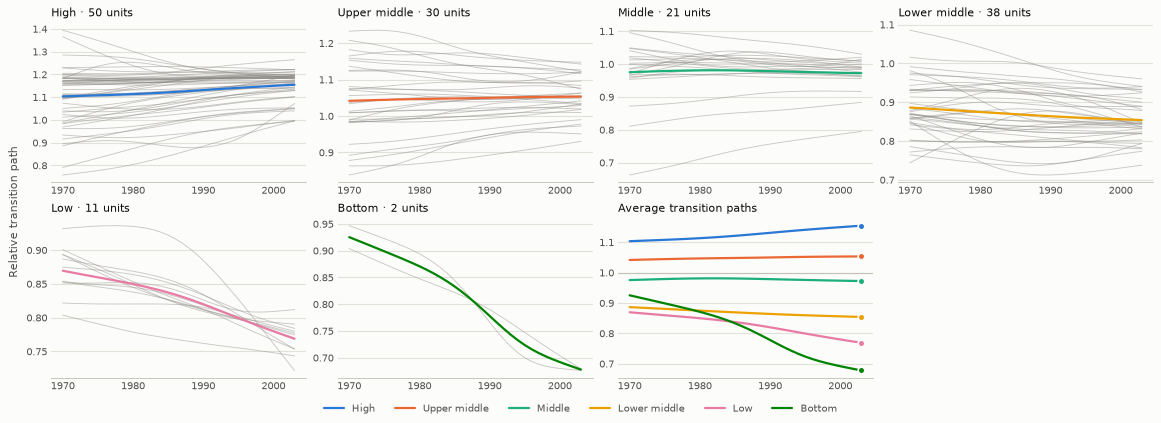

In [16]:
named.plot(ncols=4);

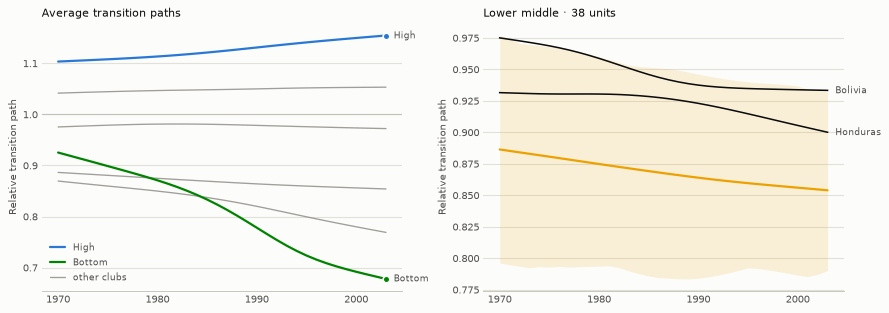

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
named.plot.average(ax=axes[0], emphasis=["High", "Bottom"])  # grey the rest
named.plot.club("Lower middle", ax=axes[1], highlight=["Bolivia", "Honduras"], units="band");

Diagnostics: the cross-sectional variation H(t), which shrinks in converging clubs, and the
log t regression of one club (with `show_discarded=True`, the first periods it leaves out).

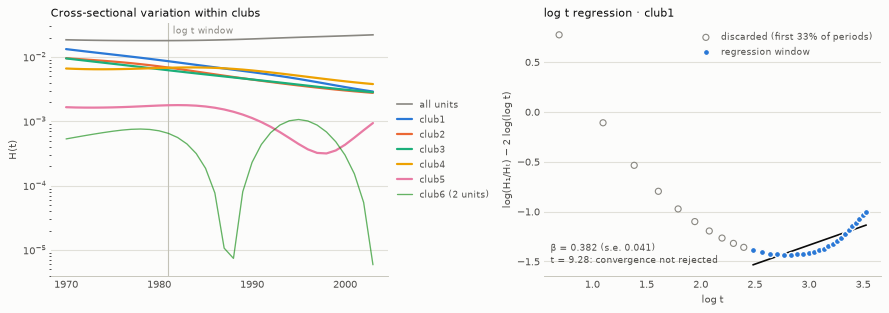

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
merged.plot.variation(ax=axes[0])
merged.plot.log_t("club1", ax=axes[1], show_discarded=True);

### Themes and style

Four built-in themes: `"light"`, `"dark"`, `"print"` (grays and line styles, for black and
white) and `"journal"` (box, no gridlines, centred titles). Pass `theme=` to one plot, or set
the default once with `cc.set_theme` or, for a block, `cc.theme_context`.

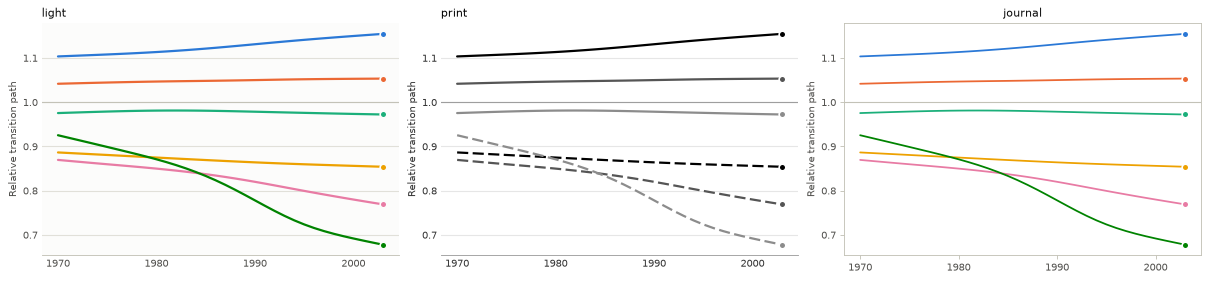

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4), layout="constrained")
for ax, theme in zip(axes, ["light", "print", "journal"], strict=True):
    merged.plot.average(ax=ax, theme=theme, title=theme, legend=False)

A figure takes the surface of its theme, so a dark plot gets a figure of its own:

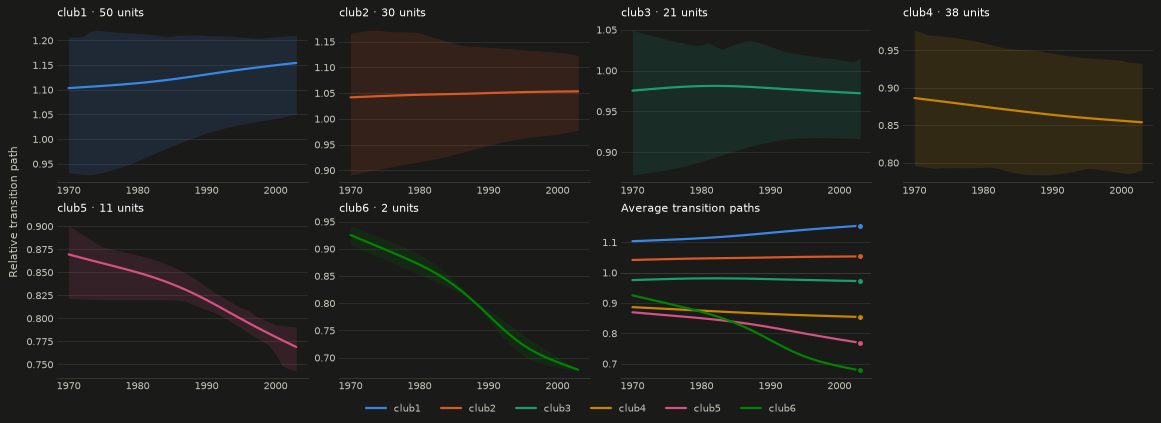

In [20]:
merged.plot(ncols=4, theme="dark", units="band");

A theme is a frozen dataclass: `replace` changes any field. Style fields apply to every plot —
`line_width`, `marker_size`, `gridlines`, `frame`, `title_loc`, `font_size` — and `colors`
holds the club colours. `register_theme` makes a theme available by name.

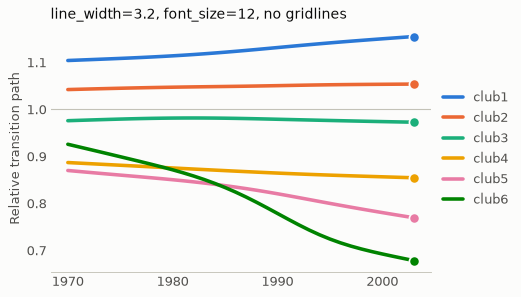

In [21]:
slides = cc.LIGHT.replace(line_width=3.2, marker_size=70, font_size=12, gridlines=False)
cc.register_theme("slides", slides)
with cc.theme_context("slides"):
    merged.plot.average(title="line_width=3.2, font_size=12, no gridlines")

Colours have three jobs: `colors` identify clubs, `sequential` shows magnitude (heatmaps), and
`ordinal` shows ordered classes (periods, or clubs on a map). `cc.ordinal_colors(n)` gives n
evenly spaced steps.

In [22]:
cc.ordinal_colors(6), cc.ordinal_colors(6, "dark")

(['#86b6ef', '#639ee6', '#3f85db', '#246ac0', '#184f94', '#0d366b'],
 ['#184f95', '#2565b4', '#327bd5', '#599aea', '#94bef4', '#cde2fb'])

## 5. Robustness

`sensitivity` reruns the clustering over a grid of settings. `ari_vs_baseline` is the
adjusted Rand index against the first run (1 = the same clubs).

In [23]:
runs = cc.sensitivity(
    trend, time_trim=[1 / 3, 0.3, 0.25], hac_method=["FQSB", "AQSB"], merge=["PS"]
)
runs.table()

,time_trim,hac_method,cstar,merge,sort_fraction,n_units,n_clubs,n_divergent,n_failing,sizes,ari_vs_baseline
0,0.333,FQSB,0.0,PS,0.0,152,6,0,0,50-30-21-38-11-2,1.000
1,0.333,AQSB,0.0,PS,0.0,152,4,3,1,84-18-40-7,0.586
2,0.300,FQSB,0.0,PS,0.0,152,6,0,0,55-43-25-22-5-2,0.663
3,0.300,AQSB,0.0,PS,0.0,152,5,1,1,79-20-22-25-5,0.554
4,0.250,FQSB,0.0,PS,0.0,152,6,0,0,54-45-19-21-11-2,0.658
5,0.250,AQSB,0.0,PS,0.0,152,5,0,1,95-23-21-11-2,0.379


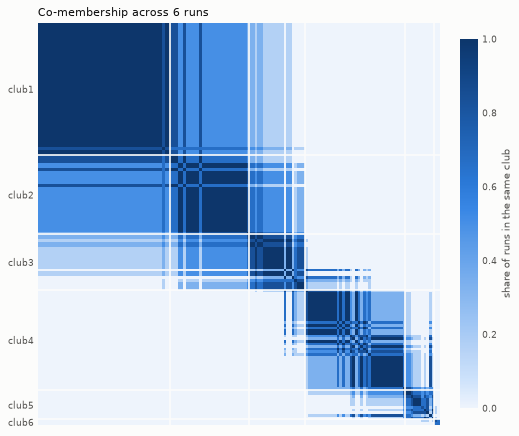

In [24]:
runs.plot();  # co-membership: share of runs in which two countries share a club

`bootstrap` perturbs the data instead: random subsamples of units (`"units"`), resampled
business cycles (`"cycle"`) or dropping the last years (`"endpoint"`). A unit's **stability**
is the share of runs in which it keeps its full-sample club mates.
`n_jobs=-1` runs the replicates on every CPU; the result does not depend on it.

In [25]:
boot = cc.bootstrap(trend, 100, merge="PS", seed=0, n_jobs=-1)
boot.uncertain(0.8).head()

,baseline_club,stability,divergent_share,n_runs
Countries,,,,
Jordan,club4,0.466,0.000,86
Vanuatu,club4,0.476,0.000,85
Somalia,club5,0.523,0.373,83
Rwanda,club5,0.543,0.111,81
"Gambia, The",club4,0.561,0.000,80


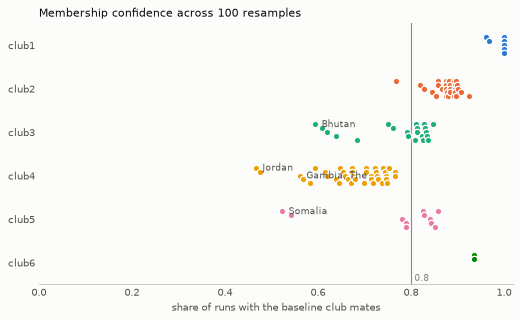

In [26]:
boot.plot_stability();

In [27]:
cycle = cc.bootstrap(np.log(gdp), 50, method="cycle", filter_lambda=400, merge="PS", seed=0)
endpoint = cc.bootstrap(trend, method="endpoint", max_drop=3, merge="PS")
pd.DataFrame(
    {
        "units": boot.stability()["stability"].describe(),
        "cycle": cycle.stability()["stability"].describe(),
        "endpoint": endpoint.stability()["stability"].describe(),
    }
).loc[["mean", "min", "25%"]]

,units,cycle,endpoint
mean,0.844,0.790,0.843
min,0.466,0.266,0.371
25%,0.743,0.686,0.716


Two results can be compared directly:

In [28]:
cc.adjusted_rand_index(merged, aqsb.merge("PS")), cc.compare_clubs(merged, aqsb.merge("PS"))

(0.5858747996913168,
 b      club1  club2  club3  club4  divergent
 a                                           
 club1     50      0      0      0          0
 club2     30      0      0      0          0
 club3      4     17      0      0          0
 club4      0      1     37      0          0
 club5      0      0      3      7          1
 club6      0      0      0      0          2)

### Clubs over time

`rolling_clubs` finds the clubs in rolling windows (here 20 years, 7 apart), HP-filtering inside
each window. `movers()` lists the countries that did not follow most of their club mates.

In [29]:
rolled = cc.rolling_clubs(np.log(gdp), window=20, step=7, filter_lambda=400)
rolled.summary()

,n_clubs,n_divergent,sizes,ari_vs_previous
window,,,,
1970–1989,5,2,"[58, 53, 6, 29, 4]",NaN
1977–1996,5,1,"[58, 35, 22, 22, 14]",0.496
1984–2003,8,1,"[45, 19, 26, 12, 22, 20, 5, 2]",0.494


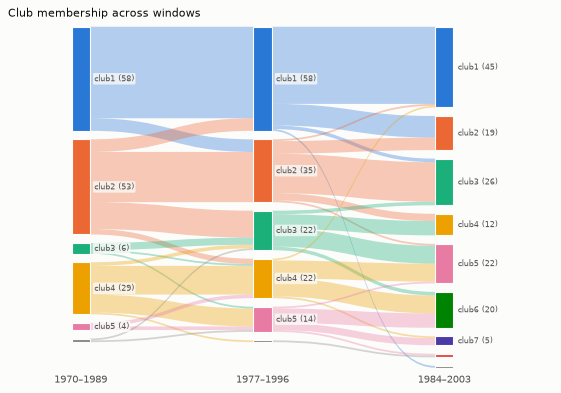

In [30]:
rolled.plot();

In [31]:
movers = rolled.movers()
movers["direction"].value_counts(), movers[movers.direction == "up"].head()

(direction
 down              76
 up                29
 from divergent     3
 to divergent       2
 Name: count, dtype: int64,
                        unit from_window  to_window from_club to_club  \
 7                 Argentina   1970–1989  1977–1996     club2   club1   
 10                    Chile   1970–1989  1977–1996     club2   club1   
 11                    China   1970–1989  1977–1996     club2   club1   
 14                 Dominica   1970–1989  1977–1996     club2   club1   
 27  St.Vincent & Grenadines   1970–1989  1977–1996     club2   club1   
 
    mates_went_to direction  
 7          club2        up  
 10         club2        up  
 11         club2        up  
 14         club2        up  
 27         club2        up  )

## 6. Classical convergence

These use the **unfiltered levels**.

**β-convergence**: do poorer countries grow faster? Absolute, conditional on clubs (club
fixed effects) and within each club.

In [32]:
absolute = cc.beta_convergence(gdp)
conditional = cc.beta_convergence(gdp, clubs=merged, club_effects=True)
absolute.summary()

,coef,std_err,t_value,p_value
term,,,,
const,1.817e-02,0.014,1.341,0.182
log_initial,-3.816e-04,0.002,-0.237,0.813


In [33]:
conditional.by_club()

,n_units,beta,std_err,t_value,p_value,speed,half_life
club1,50,-0.017,0.001,-11.261,4.509e-15,0.025,28.122
club2,30,-0.013,0.002,-8.198,6.350e-09,0.016,42.118
club3,21,-0.014,0.002,-8.953,3.028e-08,0.018,38.277
club4,38,-0.012,0.002,-4.819,2.611e-05,0.015,46.287
club5,11,-0.033,0.010,-3.101,1.270e-02,NaN,NaN
club6,2,NaN,NaN,NaN,NaN,NaN,NaN


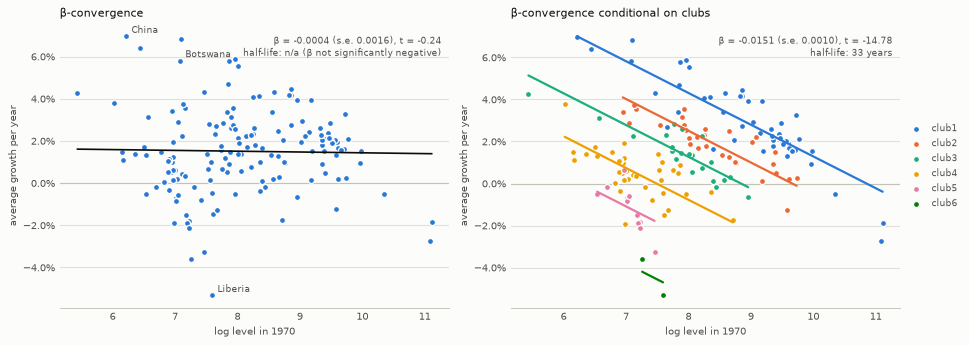

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
absolute.plot(ax=axes[0], label=["China", "Botswana", "Liberia"])
conditional.plot(ax=axes[1]);

**σ-convergence**: does the dispersion of log income shrink over time, overall and within clubs?

In [35]:
sigma = cc.sigma_convergence(gdp, clubs=merged)
sigma.trend()[["n_units", "change", "slope", "t_value", "converging"]]

,n_units,change,slope,t_value,converging
group,,,,,
all units,152,0.159,0.005,11.283,False
club1,50,-0.467,-0.015,-38.971,True
club2,30,-0.366,-0.012,-12.811,True
club3,21,-0.389,-0.010,-20.635,True
club4,38,-0.221,-0.004,-3.633,True
club5,11,-0.125,-0.005,-3.554,True


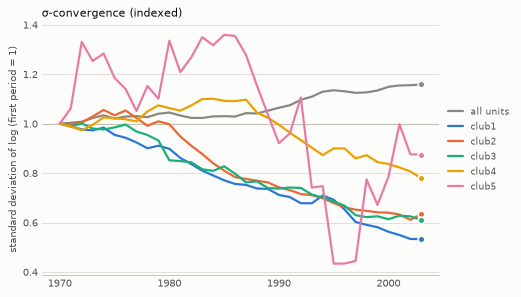

In [36]:
sigma.plot(index=True);

**Distribution dynamics** (Quah): transition probabilities between classes of relative income,
the long-run (ergodic) distribution and "twin peaks".

In [37]:
dynamics = cc.distribution_dynamics(gdp, lag=5, clubs=merged)
dynamics.summary()

classes                 5.000
lag                     5.000
transitions          4408.000
shorrocks               0.174
second_eigenvalue       0.981
half_life             178.051
dtype: float64

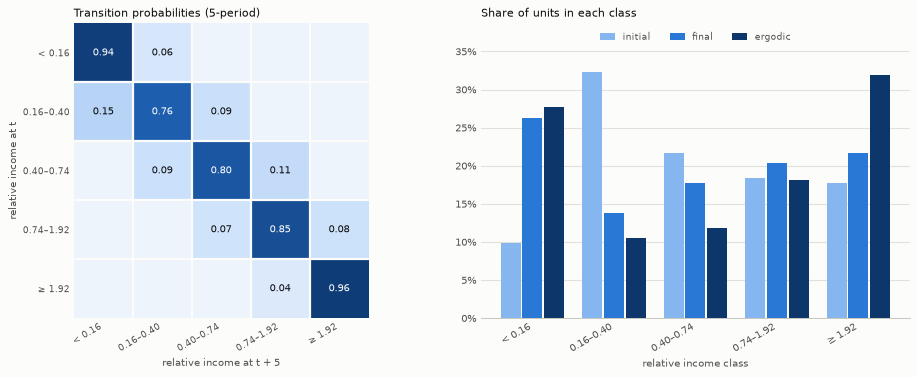

In [38]:
dynamics.plot();

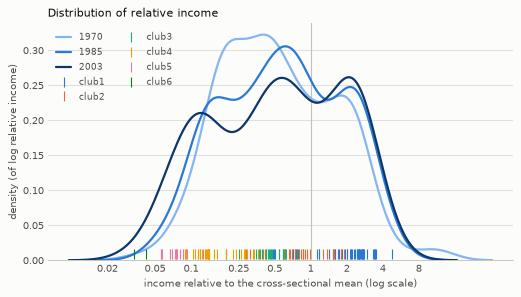

In [39]:
dynamics.plot_densities(periods=[1970, 1985, 2003]);

**Pesaran's (2007) pairwise test**: an ADF test on the gap between every pair of countries
(11,476 pairs), confirmed with KPSS. Without convergence about 5% of pairs reject the unit root.
`n_jobs=-1` spreads the pairs over every CPU.

In [40]:
pairwise = cc.pairwise_convergence(gdp, clubs=merged, kpss=True, n_jobs=-1)
pairwise.summary()

,n_pairs,share_rejected,expected_under_null,share_kpss_stationary,share_both_agree
pairs,,,,,
all pairs,11476,0.128,0.05,0.282,0.063
within clubs,2629,0.159,0.05,0.389,0.080
between clubs,8847,0.118,0.05,0.250,0.058


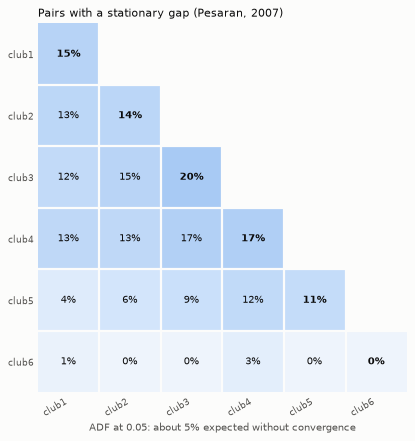

In [41]:
pairwise.plot();  # share of stationary gaps within (diagonal) and between clubs

## 7. Determinants of club membership

Which initial conditions predict a higher club? An ordered logit (or probit) of the club on
unit-level covariates, here with the productivity panel of Mendez (2020).

In [42]:
lp_all = cc.load_productivity("lp")
lp_clubs = cc.find_clubs(cc.hp_filter(np.log(lp_all)), convention="Stata", time_trim=0.333).merge(
    "PS"
)
info = cc.productivity_info()
covariates = pd.DataFrame(
    {
        "log human capital, 1990": np.log(cc.load_productivity("h")[1990]),
        "log capital-output ratio, 1990": np.log(cc.load_productivity("ky")[1990]),
        "Africa": (info["region"] == "Africa").astype(float),
    }
)
fit = cc.club_determinants(lp_clubs, covariates)
fit.summary()

,coef,std_err,z_value,p_value,odds_ratio
covariate,,,,,
"log human capital, 1990",8.467,2.057,4.116,3.858e-05,4754.553
"log capital-output ratio, 1990",-1.759,0.630,-2.790,5.278e-03,0.172
Africa,-2.444,0.747,-3.273,1.065e-03,0.087


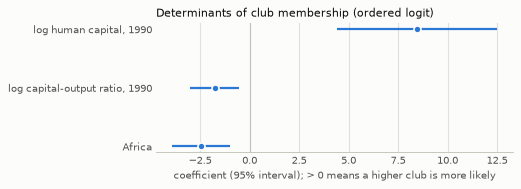

In [43]:
fit.plot();

## 8. Output

**Interactive charts** (plotly, `interactive` extra): hover shows each unit. They are not
displayed here to keep the notebook small; `write_html` saves them as a standalone page.

In [44]:
chart = named.plot.interactive(kind="both")
chart.write_html("clubs.html")
len(chart.data), "traces"

(164, 'traces')

**Maps** (`maps` extra) need region boundaries, e.g. Natural Earth:

```python
import geopandas as gpd

world = gpd.read_file("https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip")
merged.plot.map(world, key="ISO_A3_EH", names=cc.country_codes(), crs="EPSG:8857", confidence=boot)
```

![Map of the clubs](map.png)

Are the clubs spatially clustered? `spatial_clustering` counts the pairs of neighbouring
countries in the same club and compares them with random assignments of the same club sizes:

```python
nb = cc.neighbours(world, merged.data.index, key="ISO_A3_EH", names=cc.country_codes())
spatial = cc.spatial_clustering(merged, nb, seed=0)
spatial.summary()   # 75 of 187 neighbour pairs share a club: 1.75 x random, p = 0.001
spatial.plot()
```

![Joins within each club relative to random assignment](spatial.png)

**Report**: one call runs the standard analysis and writes a self-contained HTML file that
can serve as a replication appendix ([example](report-example.html)).

In [45]:
report = cc.report(
    gdp,
    bootstrap=30,
    club_names=named.summary().index.tolist(),
    title="Convergence clubs in GDP per capita",
    n_jobs=-1,
)
[section.title for section in report.sections], report.save("report.html").name

(['Data and settings',
  'Convergence of the whole panel',
  'Convergence clubs',
  'Robustness',
  'β-convergence',
  'σ-convergence',
  'Distribution dynamics',
  'Methods and references'],
 'report.html')

**Command line**: the same analyses without writing Python
(`convergence-clubs gdp.csv --log --hp-filter --merge PS ...`). Here it is called from Python.

In [46]:
from convergence_clubs.cli import main

gdp.to_csv("gdp.csv")
exit_code = main(
    [
        "gdp.csv",
        "--log",
        "--hp-filter",
        "--merge",
        "PS",
        "--club-names",
        "High; Upper middle; Middle; Lower middle; Low; Bottom",
        "--summary",
        "summary.csv",
        "--plot",
        "clubs.png",
        "--theme",
        "journal",
    ]
)

6 convergence clubs, 0 divergent units

              n_units   beta  std_err  t_value  p_value  converges  merged_clubs
club                                                                            
High               50  0.382    0.041    9.282    1.000       True         club1
Upper middle       30  0.240    0.035    6.904    1.000       True         club2
Middle             21  0.110    0.032    3.402    1.000       True         club3
Lower middle       38 -0.044    0.070   -0.636    0.262       True  club4, club5
Low                11  1.003    0.166    6.024    1.000       True         club6
Bottom              2 -0.470    0.842   -0.559    0.288       True         club7


In [47]:
exit_code, pd.read_csv("summary.csv", index_col="club")[["n_units", "t_value"]]

(0,
               n_units  t_value
 club                          
 High               50    9.282
 Upper middle       30    6.904
 Middle             21    3.402
 Lower middle       38   -0.636
 Low                11    6.024
 Bottom              2   -0.559)

**LaTeX tables** for papers: the clubs with their size, log t coefficient, t statistic and
members (booktabs; `longtable` when the lists are long), and any results table with
`cc.to_latex`. No extra Python package is needed.

In [48]:
print(named.to_latex(members=False, label="tab:clubs"))

% Needs \usepackage{booktabs}
\begin{table}[htbp]
\centering
\caption{Convergence clubs after merging}
\label{tab:clubs}
\begin{tabular}{lrrr}
\toprule
Club & $N$ & $\hat\beta$ & $t$ \\
\midrule
High & 50 & 0.382 & 9.28 \\
Upper middle & 30 & 0.240 & 6.90 \\
Middle & 21 & 0.110 & 3.40 \\
Lower middle & 38 & $-$0.044 & $-$0.64 \\
Low & 11 & 1.003 & 6.02 \\
Bottom & 2 & $-$0.470 & $-$0.56 \\
\bottomrule
\end{tabular}
\par\smallskip{\footnotesize\raggedright Log $t$ test of Phillips and Sul (2007): convergence is rejected at 5\% when $t < -1.65$. FQSB standard errors, the first 0.333 of the periods discarded, R convention, adjacent clubs merged.\par}
\end{table}



In [49]:
named.to_latex(path="clubs.tex")  # with the members, written to a file
print(
    cc.to_latex(
        conditional.by_club()[["n_units", "beta", "half_life"]], header={"beta": r"$\hat\beta$"}
    )
)

% Needs \usepackage{booktabs}
\begin{table}[htbp]
\centering
\begin{tabular}{lrrr}
\toprule
 & n\_units & $\hat\beta$ & half\_life \\
\midrule
club1 & 50 & $-$0.017 & 28.122 \\
club2 & 30 & $-$0.013 & 42.118 \\
club3 & 21 & $-$0.014 & 38.277 \\
club4 & 38 & $-$0.012 & 46.287 \\
club5 & 11 & $-$0.033 &  \\
club6 & 2 &  &  \\
\bottomrule
\end{tabular}
\end{table}



## Where next

- [Tutorial](tutorial.ipynb): the same analysis, explaining how to read each result.
- [Guides](guide/): every option, the R and Stata conventions, validation and references.